In [97]:
!pip install pystan~=2.14
!pip install fbprophet

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [98]:
## Load the required packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
import copy
import datetime
import time as thetime # (I know it's messy to rename as 'thetime', but 'time' is used elsewhere)
import operator # So that it is possible to sort a dictionary on the values

import multiprocessing
from multiprocessing import Pool # To run models in multiple threads simultaneously

# To display tables in HTML output
from IPython.display import HTML, display
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose as sm

# Tell the notebook to do inline charts
%matplotlib inline
from fbprophet import Prophet
from sklearn.metrics import mean_squared_error

# The location of the data
FOOTFALL_FILE = "/content/drive/MyDrive/footfall_data.csv"
WEATHER_FILE = "/content/drive/MyDrive/Daily Weather data.csv"

In [99]:
# Data Processing

def process_data(file):
        
        location_dict = {"Argyll Street near Queen Street Junction" : "Argyll St." , "Buchanan Street near Buchanan Galleries Entrance" : "Buchanan St.1",
    "Buchanan Street near Gordon Street Junction" : "Buchanan St.2", "Sauchiehall Street near Wellington Street Junction" : "Sauchiehall St.1",
     "194 Bath Street (near Blythswood Street Junction)" : "Bath Street", "Sauchiehall Street near Elmbank Street Junction" : "Sauchiehall St.2",
     "253 High Street (near George Street Junction)" : "High Street" }
        
        file['LocationName'] = file['LocationName'].map(location_dict) 

        if 'ProccessedDate' not in file:
            file['ProccessedDate'] = pd.to_datetime(file["processDate"]).apply(lambda x: x.date())

        weather_file = pd.read_csv(WEATHER_FILE)
        weather_file = weather_file.fillna(0)
        
        file = file.groupby(['ProccessedDate','LocationName']).agg({'pedestrianCount': 'mean'}).reset_index()
        # file = file.groupby(['ProccessedDate','LocationName'])['pedestrianCount'].sum()
        file['Date'] =  pd.to_datetime(file['ProccessedDate']).dt.strftime('%d/%m/%Y')

        merged_data = pd.merge(file,weather_file[['Date','Temperature','tmin','tmax','wspd']],on="Date", how='left')
        merged_data = merged_data.fillna(0)
        return merged_data

In [4]:
# filtering Argyll Street
file = pd.read_csv(FOOTFALL_FILE) # reading footfall data
file= file[file['pedestrianCount'] != 0]
file = process_data(file) # process_data function has the data-processing functionality
temp_file = file[file['LocationName']=='Argyll St.'] 

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


In [5]:
file.head()

,ProccessedDate,LocationName,pedestrianCount,Date,Temperature,tmin,tmax,wspd
0,2018-02-23,Argyll St.,1764.416667,23/02/2018,2.4,0.0,6.0,12.5
1,2018-02-23,Bath Street,190.875000,23/02/2018,2.4,0.0,6.0,12.5
2,2018-02-23,Buchanan St.1,1307.833333,23/02/2018,2.4,0.0,6.0,12.5
3,2018-02-23,Buchanan St.2,1336.916667,23/02/2018,2.4,0.0,6.0,12.5
4,2018-02-23,Sauchiehall St.1,1922.041667,23/02/2018,2.4,0.0,6.0,12.5


In [6]:
#splitting up the test and train
mask1 = temp_file[(temp_file['ProccessedDate']>datetime.date(2018,1,1)) & (temp_file['ProccessedDate']<=datetime.date(2020,1,31))]
mask2 = temp_file[(temp_file['ProccessedDate'] > datetime.date(2020,2,1)) & (temp_file['ProccessedDate'] <= datetime.date(2020,3,1))]
train = mask1
test = mask2
df = train
original_data = train.append(test)

In [7]:
# renaming the columns
train = train.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
train['y_orig'] = train['y'] # to save a copy of the original data..you'll see why shortly. 
train['y'] = np.log(train['y'])

In [8]:
# initating prophet model with weekly and yearly seasonality to be true
model = Prophet(weekly_seasonality=True,yearly_seasonality=True, daily_seasonality=True) 
# adding the country's  holiday
model.add_country_holidays(country_name='UK')
# adding the multivariate variables to the model
model.add_regressor('Temperature')
model.add_regressor('tmin')
model.add_regressor('tmax')
model.add_regressor('wspd')
# now fitting the model with the training data
model.fit(train)

In [9]:
''' 'year': 'A',
        'quarter': 'Q',
        'month': 'M',
        'day': 'D',
        'hour': 'H',
        'minute': 'T',
        'second': 'S',
        'millisecond': 'L',
        'microsecond': 'U',
        'nanosecond': 'N'}1
'''

# making the future dataframe
future_data = model.make_future_dataframe(periods=90)

In [ ]:
future_data.tail()

,ds
793,2020-04-26
794,2020-04-27
795,2020-04-28
796,2020-04-29
797,2020-04-30


In [10]:
# getting the regressor column values
df=df.append(test)
df = df.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
future_data=df[[ 'ds','Temperature', 'tmin', 'tmax','wspd']]
future_data.tail(5)

,ds,Temperature,tmin,tmax,wspd
4442,2020-02-26,2.2,-1.0,6.0,16.3
4449,2020-02-27,2.3,0.0,5.0,16.0
4456,2020-02-28,3.5,2.0,5.0,13.2
4463,2020-02-29,4.3,3.0,7.0,24.2
4470,2020-03-01,4.8,3.0,7.0,36.6


In [11]:
# predicting the data
forecast_data = model.predict(future_data)

forecast_data[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(5)

,ds,yhat,yhat_lower,yhat_upper
732,2020-02-26,7.362902,7.195042,7.543022
733,2020-02-27,7.430515,7.248320,7.604451
734,2020-02-28,7.524189,7.349558,7.687622
735,2020-02-29,7.463584,7.294969,7.635123
736,2020-03-01,6.986291,6.811182,7.157292


In [ ]:
from fbprophet.plot import plot_components_plotly
plot_components_plotly(model,forecast_data)

In [ ]:
from fbprophet.plot import plot_plotly
plot_plotly(model,forecast_data)

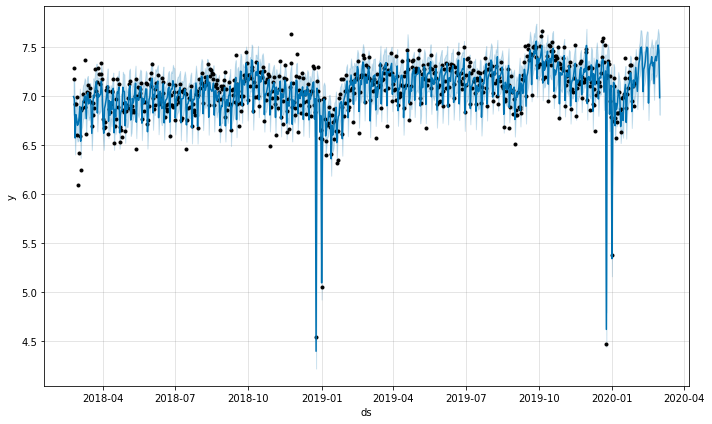

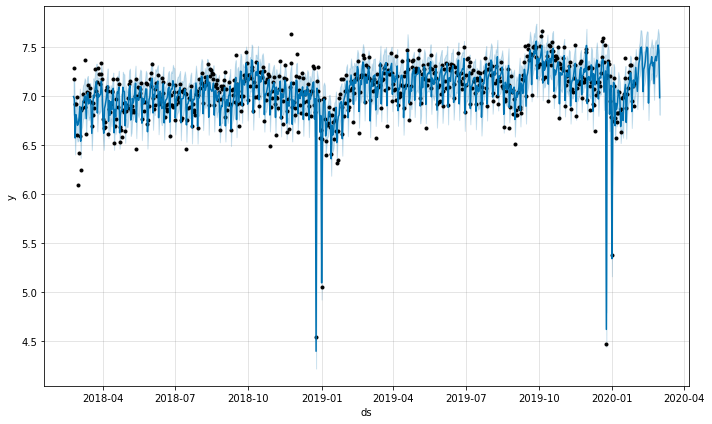

In [12]:

model.plot(forecast_data)

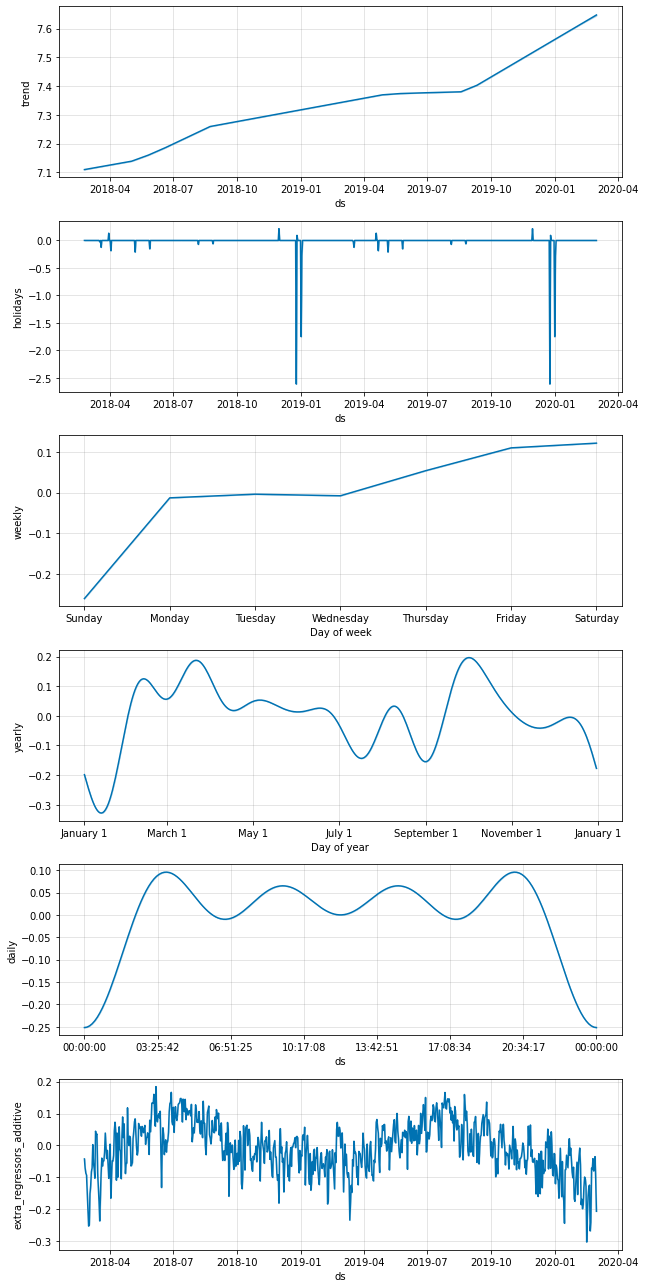

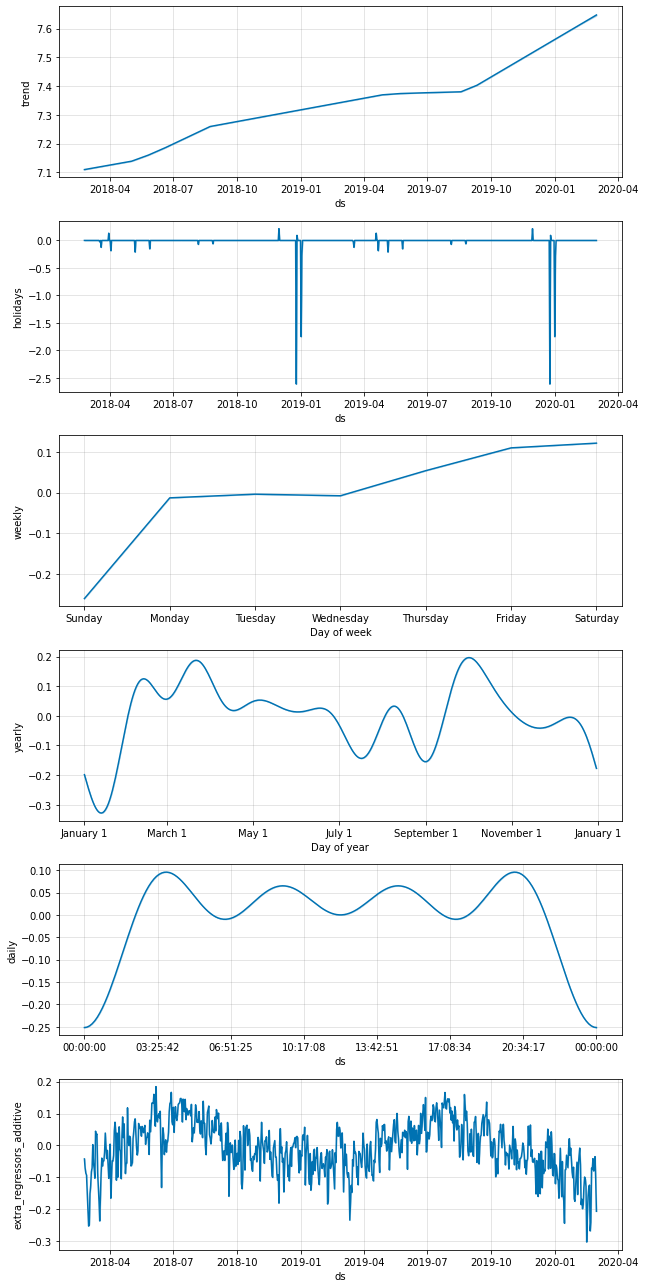

In [13]:
model.plot_components(forecast_data)


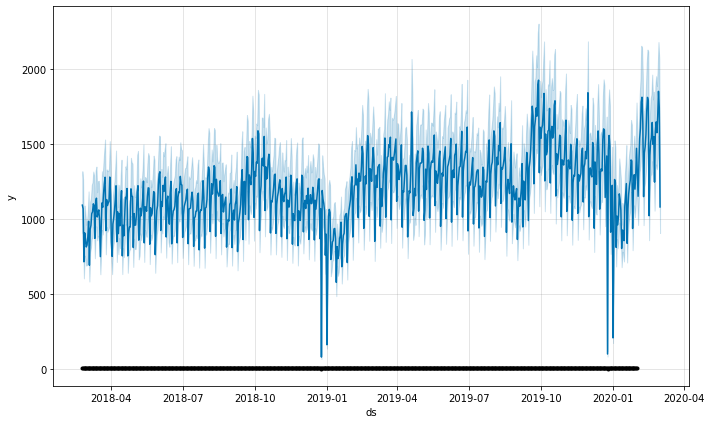

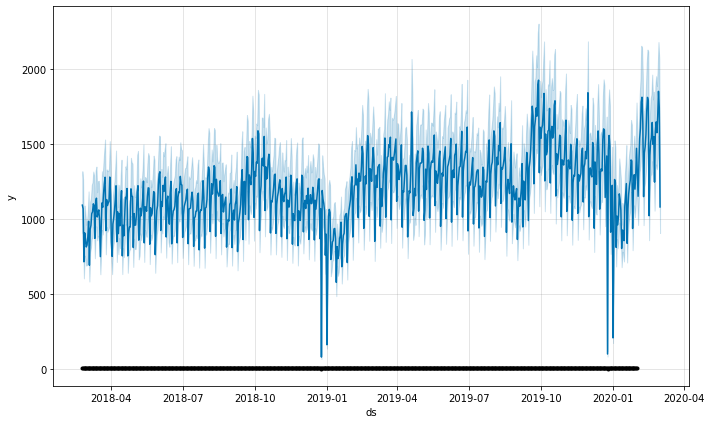

In [18]:
forecast_data_orig = forecast_data # make sure we save the original forecast data
forecast_data_orig['yhat'] = np.exp(forecast_data_orig['yhat'])
forecast_data_orig['yhat_lower'] = np.exp(forecast_data_orig['yhat_lower'])
forecast_data_orig['yhat_upper'] = np.exp(forecast_data_orig['yhat_upper'])

model.plot(forecast_data_orig)

In [ ]:
from fbprophet.utilities import regressor_coefficients

regressor_df = regressor_coefficients(model)

In [ ]:
regressor_df

,regressor,regressor_mode,center,coef_lower,coef,coef_upper
0,Temperature,additive,9.630367,-0.004864,-0.004864,-0.004864
1,tmin,additive,6.025424,0.002019,0.002019,0.002019
2,tmax,additive,13.028249,0.010550,0.010550,0.010550
3,wspd,additive,15.753390,-0.005676,-0.005676,-0.005676


In [ ]:
train['y_log']=train['y'] #copy the log-transformed data to another column
train['y']=train['y_orig']

In [19]:
final_df = pd.DataFrame(forecast_data_orig)
import plotly.graph_objs as go
import plotly.offline as py
#Plot predicted and actual line graph with X=dates, Y=Outbound
actual_chart = go.Scatter(y=train["y_orig"], name= 'Actual')
predict_chart = go.Scatter(y=final_df["yhat"], name= 'Predicted')
predict_chart_upper = go.Scatter(y=final_df["yhat_upper"], name= 'Predicted Upper')
predict_chart_lower = go.Scatter(y=final_df["yhat_lower"], name= 'Predicted Lower')
py.plot([actual_chart, predict_chart, predict_chart_upper, predict_chart_lower])

'temp-plot.html'

In [14]:
def mean_absolute_percentage_error(test, pred): 
    test, pred = np.array(test), np.array(pred)
    return np.mean(np.abs((test - pred) / test)) * 100

In [20]:
strt='2020-02-01'
end='2020-03-01'
Actual = final_df[(final_df['ds']>strt) & (final_df['ds']<=end)]
mape = mean_absolute_percentage_error(test['pedestrianCount'],Actual['yhat'])
print("MAPE",round(mape,4))

MAPE 25.8068


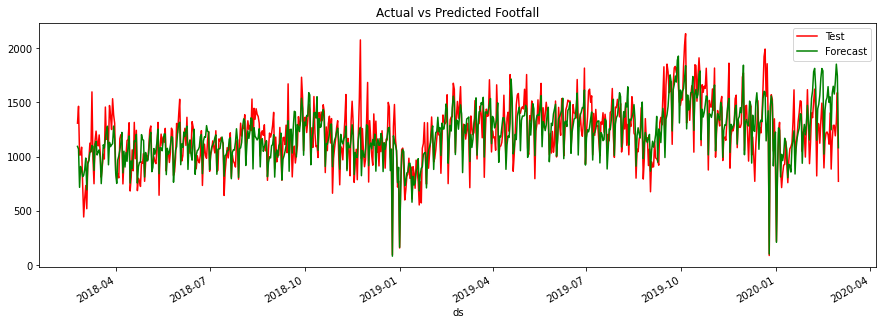

In [21]:
f, ax = plt.subplots(figsize=(14,5))
f.set_figheight(5)
f.set_figwidth(15)
original_data.plot(kind='line',x='ProccessedDate', y='pedestrianCount', color='red', label='Test', ax=ax)
forecast_data.plot(kind='line',x='ds',y='yhat', color='green',label='Forecast', ax=ax)
plt.title('Actual vs Predicted Footfall')
plt.show()

In [22]:
from sklearn.model_selection import ParameterGrid
params_grid = {'seasonality_mode':('multiplicative','additive'),
               'changepoint_prior_scale':[0.1,0.2,0.3,0.4,0.5],
              'holidays_prior_scale':[0.1,0.2,0.3,0.4,0.5],
              'n_changepoints' : [100,150,200]}
grid = ParameterGrid(params_grid)
cnt = 0
for p in grid:
    cnt = cnt+1

print('Total Possible Models',cnt)

Total Possible Models 150


In [24]:
import holidays
import random
holiday = pd.DataFrame([])
for date, name in sorted(holidays.UnitedKingdom(years=[2018,2019,2020,2021,2022]).items()):
    holiday = holiday.append(pd.DataFrame({'ds': date, 'holiday': "UK-Holidays"}, index=[0]), ignore_index=True)
holiday['ds'] = pd.to_datetime(holiday['ds'], format='%Y-%m-%d', errors='ignore')

In [ ]:
train

,ds,LocationName,y,Date,Temperature,tmin,tmax,wspd,y_orig,y_log
4734,2020-04-08,Argyll St.,164.250000,08/04/2020,10.2,5.0,15.0,14.6,164.250000,5.101390
5777,2020-09-04,Argyll St.,1256.750000,04/09/2020,13.2,11.0,16.0,27.1,1256.750000,7.136284
6148,2020-10-27,Argyll St.,816.250000,27/10/2020,6.9,4.0,9.0,11.8,816.250000,6.704721
1596,2018-11-16,Argyll St.,2024.708333,16/11/2018,9.2,4.0,13.0,7.8,2024.708333,7.613181
8521,2021-10-01,Argyll St.,1520.125000,01/10/2021,10.5,8.0,13.0,23.6,1520.125000,7.326548
...,...,...,...,...,...,...,...,...,...,...
102,2018-03-12,Argyll St.,1507.083333,12/03/2018,6.1,4.0,8.0,7.7,1507.083333,7.317931
3276,2019-08-23,Argyll St.,2127.958333,23/08/2019,17.3,15.0,20.0,22.9,2127.958333,7.662918
1980,2019-01-19,Argyll St.,1614.708333,19/01/2019,2.6,1.0,4.0,9.7,1614.708333,7.386910
8206,2021-08-17,Argyll St.,1176.291667,17/08/2021,16.0,14.0,19.0,18.3,1176.291667,7.070122


In [30]:
strt='2020-2-1'
end='2020-03-1'

model_parameters = pd.DataFrame(columns = ['MAPE','Parameters'])
for p in grid:
    mask1_h = temp_file[(temp_file['ProccessedDate']>datetime.date(2018,1,1)) & (temp_file['ProccessedDate']<=datetime.date(2020,1,31))]
    mask2_h = temp_file[(temp_file['ProccessedDate'] > datetime.date(2020,2,1)) & (temp_file['ProccessedDate'] <= datetime.date(2020,3,1))]
    train_h = mask1_h
    test_h = mask2_h
    df_h = train_h
    original_data_h = train_h.append(test)

    train_h = train_h.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
    # train_h['y_orig'] = train_h['y'] # to save a copy of the original data..you'll see why shortly. 
    # train_h['y'] = np.log(train_h['y'])
    testAc = pd.DataFrame()
    print(p)
    random.seed(0)
    train_model =Prophet(changepoint_prior_scale = p['changepoint_prior_scale'],
                         holidays_prior_scale = p['holidays_prior_scale'],
                         n_changepoints = p['n_changepoints'],
                         seasonality_mode = p['seasonality_mode'],
                         weekly_seasonality=True,
                         yearly_seasonality = True,
                         daily_seasonality=True,
                         holidays=holiday, 
                         interval_width=0.95)
    train_model.add_country_holidays(country_name='UK')
    train_model.fit(train_h)
    train_forecast = train_model.make_future_dataframe(periods=90)
    train_forecast = train_model.predict(train_forecast)
    test=train_forecast[['ds','yhat']]
    Actual = test[(test['ds']>strt) & (test['ds']<=end)]
    MAPE = mean_absolute_percentage_error(test_h['pedestrianCount'],abs(Actual['yhat']))
    print('Mean Absolute Percentage Error(MAPE)------------------------------------',MAPE)
    model_parameters = model_parameters.append({'MAPE':MAPE,'Parameters':p},ignore_index=True)

{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 100, 'seasonality_mode': 'multiplicative'}
Mean Absolute Percentage Error(MAPE)------------------------------------ 22.983050328935196
{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 100, 'seasonality_mode': 'additive'}
Mean Absolute Percentage Error(MAPE)------------------------------------ 22.813302115559058
{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 150, 'seasonality_mode': 'multiplicative'}
Mean Absolute Percentage Error(MAPE)------------------------------------ 23.433827411607698
{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 150, 'seasonality_mode': 'additive'}
Mean Absolute Percentage Error(MAPE)------------------------------------ 22.771005585913233
{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 200, 'seasonality_mode': 'multiplicative'}
Mean Absolute Percentage Erro

In [31]:
parameters = model_parameters.sort_values(by=['MAPE'])
parameters = parameters.reset_index(drop=True)
parameters.head()

,MAPE,Parameters
0,22.498941,"{'changepoint_prior_scale': 0.1, 'holidays_pri..."
1,22.656971,"{'changepoint_prior_scale': 0.1, 'holidays_pri..."
2,22.771006,"{'changepoint_prior_scale': 0.1, 'holidays_pri..."
3,22.771122,"{'changepoint_prior_scale': 0.1, 'holidays_pri..."
4,22.813302,"{'changepoint_prior_scale': 0.1, 'holidays_pri..."


In [32]:
parameters['Parameters'][0]

{'changepoint_prior_scale': 0.1,
 'holidays_prior_scale': 0.1,
 'n_changepoints': 200,
 'seasonality_mode': 'multiplicative'}

In [44]:
from sklearn.model_selection import train_test_split
from fbprophet import Prophet
from sklearn.metrics import mean_squared_error
temp_file1 = file[file['LocationName']=='Buchanan St.1']
mask = temp_file1[(temp_file1['ProccessedDate']>datetime.date(2018,1,1)) & (temp_file1['ProccessedDate']<=datetime.date(2020,1,31))]
mask_2 = temp_file1[(temp_file1['ProccessedDate'] > datetime.date(2020,2,1)) & (temp_file1['ProccessedDate'] <= datetime.date(2020,3,1))]
train_f = mask
test_f = mask_2
df_f = train_f
original_data_f = train_f.append(test_f)

In [45]:
train_f = train_f.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
train_f['y_orig'] = train_f['y'] # to save a copy of the original data..you'll see why shortly. 
train_f['y'] = np.log(train_f['y'])

final_model = Prophet( holidays=holiday,
                      changepoint_prior_scale= 0.2,
                      holidays_prior_scale = 0.1,
                      n_changepoints = 200,
                      seasonality_mode = 'multiplicative',
                      weekly_seasonality=True,
                      yearly_seasonality = True,
                      interval_width=0.95) #instantiate Prophet
final_model.add_seasonality(name='daily', period=1, fourier_order=15)
final_model.add_country_holidays(country_name='UK')
final_model.add_regressor('Temperature')
final_model.add_regressor('tmin')
final_model.add_regressor('tmax')
final_model.add_regressor('wspd')

In [46]:
final_model.fit(train_f)

''' 'year': 'A',
        'quarter': 'Q',
        'month': 'M',
        'day': 'D',
        'hour': 'H',
        'minute': 'T',
        'second': 'S',
        'millisecond': 'L',
        'microsecond': 'U',
        'nanosecond': 'N'}
'''

#future_data = model.make_future_dataframe(periods=6, freq = 'H')
future_data1 = final_model.make_future_dataframe(periods=90)

INFO:fbprophet:Found custom seasonality named 'daily', disabling built-in 'daily' seasonality.


In [47]:
df_f=df_f.append(test_f)
df_f = df_f.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
future_data1=df_f[[ 'ds','Temperature', 'tmin', 'tmax','wspd']]
future_data1

,ds,Temperature,tmin,tmax,wspd
2,2018-02-23,2.4,0.0,6.0,12.5
8,2018-02-24,2.0,-2.0,7.0,14.6
14,2018-02-25,2.0,-2.0,6.0,16.2
20,2018-02-26,0.3,-5.0,5.0,13.7
26,2018-02-27,-0.3,-6.0,4.0,19.0
...,...,...,...,...,...
4442,2020-02-26,2.2,-1.0,6.0,16.3
4449,2020-02-27,2.3,0.0,5.0,16.0
4456,2020-02-28,3.5,2.0,5.0,13.2
4463,2020-02-29,4.3,3.0,7.0,24.2


In [48]:
forecast_data1 = final_model.predict(future_data1)

forecast_data1[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(5)

,ds,yhat,yhat_lower,yhat_upper
732,2020-02-26,7.479731,7.209212,7.735687
733,2020-02-27,7.550595,7.297355,7.822761
734,2020-02-28,7.652260,7.388937,7.907280
735,2020-02-29,7.592776,7.333395,7.850428
736,2020-03-01,7.080214,6.803685,7.364948


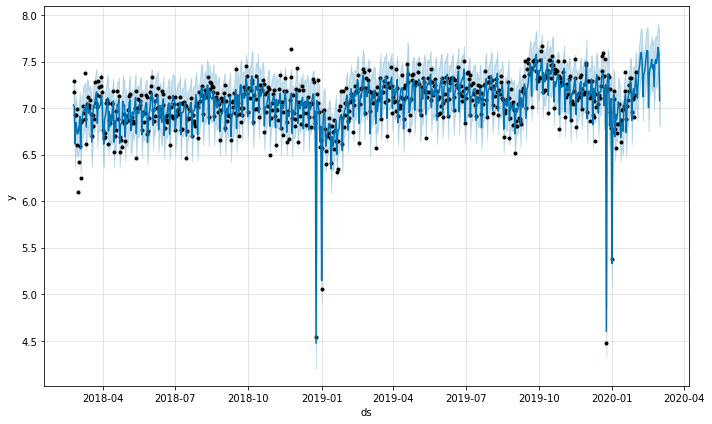

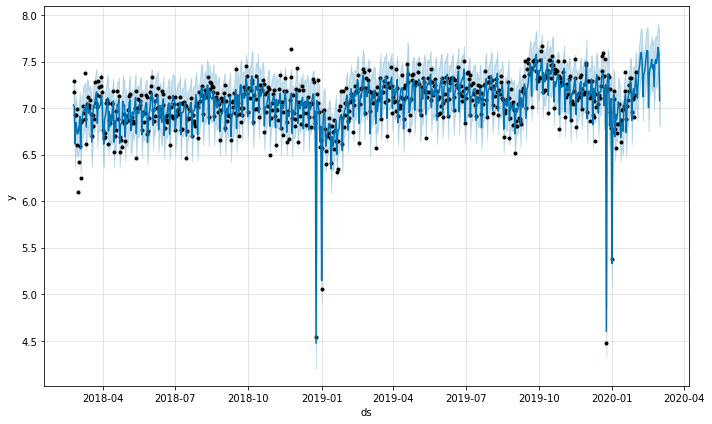

In [49]:
final_model.plot(forecast_data1)

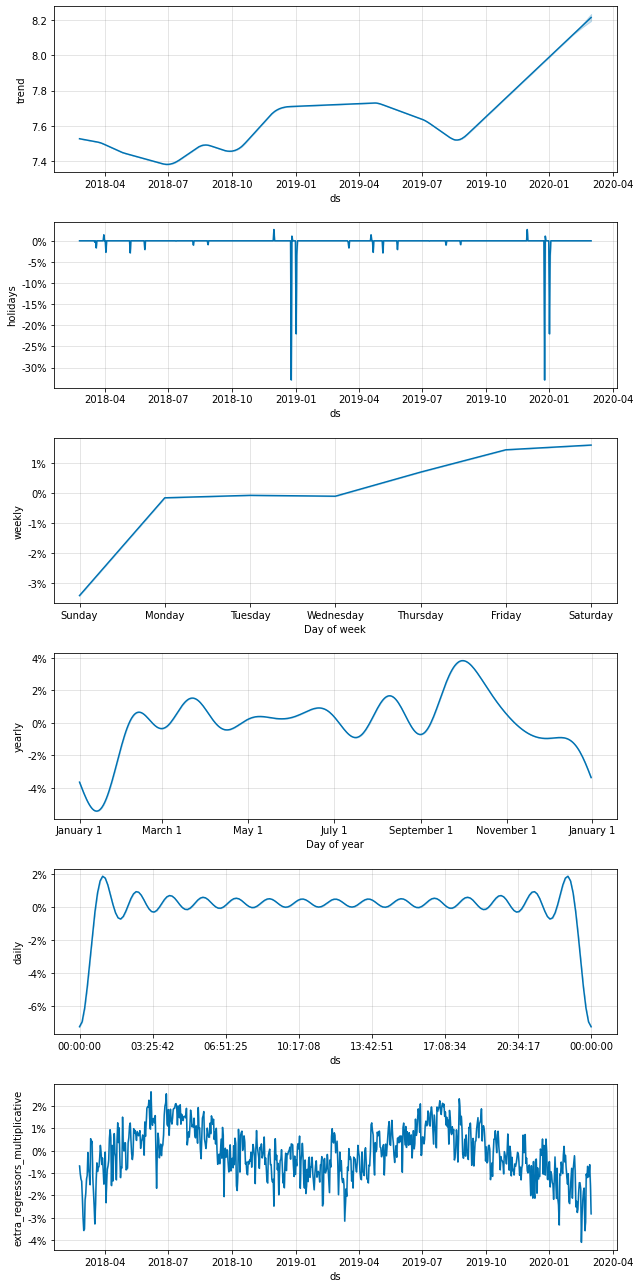

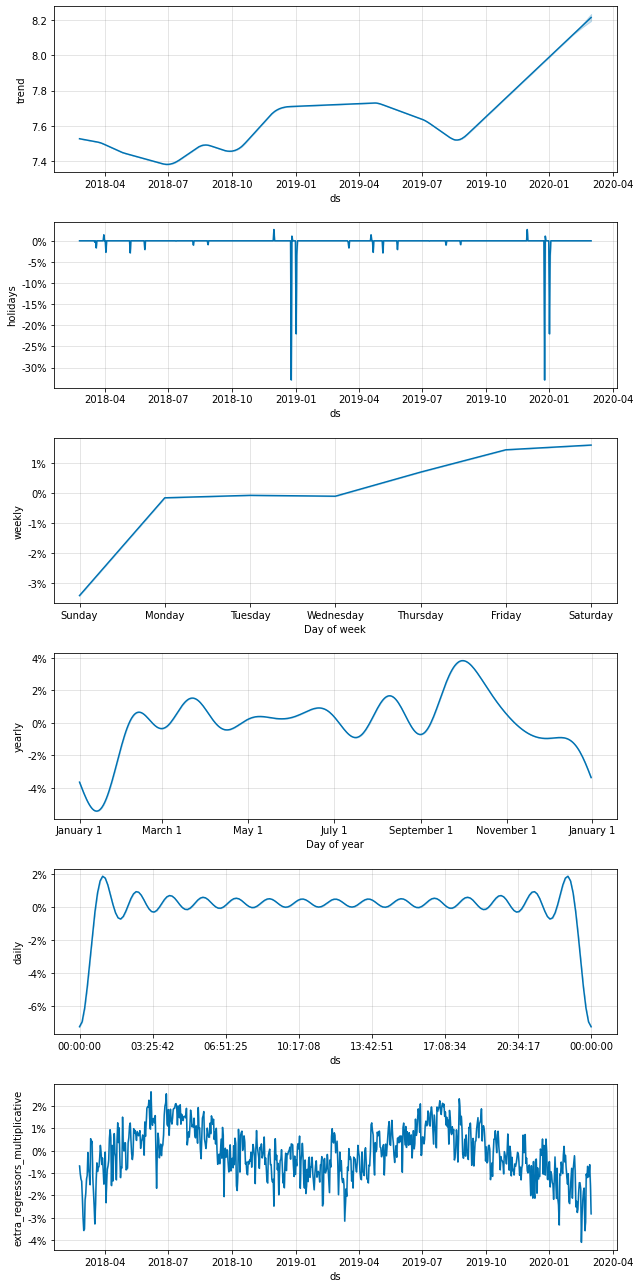

In [50]:
final_model.plot_components(forecast_data1)

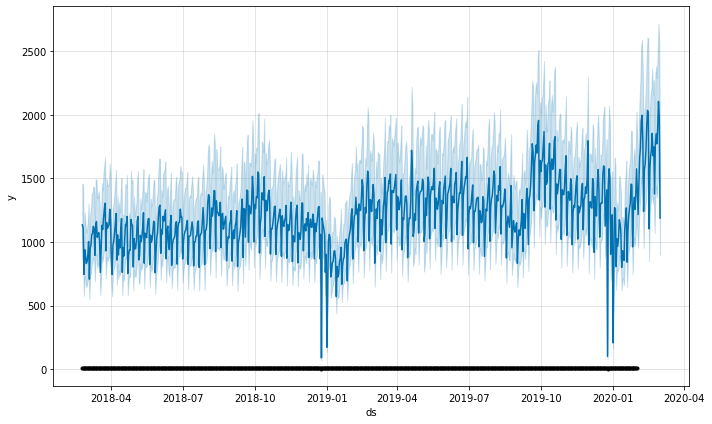

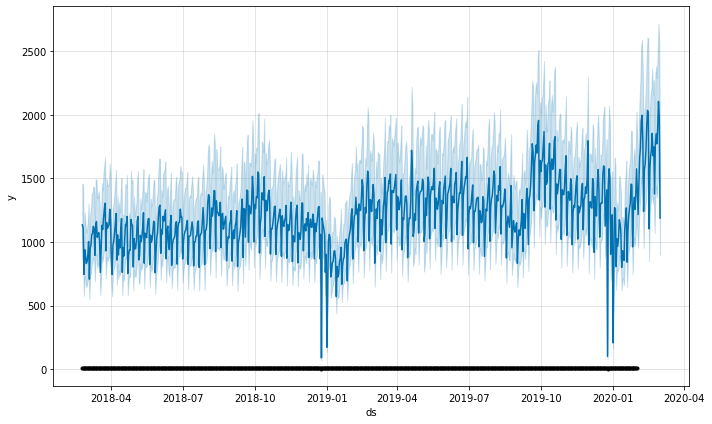

In [51]:
forecast_data_orig1 = forecast_data1 # make sure we save the original forecast data
forecast_data_orig1['yhat'] = np.exp(forecast_data_orig1['yhat'])
forecast_data_orig1['yhat_lower'] = np.exp(forecast_data_orig1['yhat_lower'])
forecast_data_orig1['yhat_upper'] = np.exp(forecast_data_orig1['yhat_upper'])

final_model.plot(forecast_data_orig1)

In [52]:
train_f['y_log']=train_f['y'] #copy the log-transformed data to another column
train_f['y']=train_f['y_orig']

In [53]:
final_df1 = pd.DataFrame(forecast_data_orig1)
import plotly.graph_objs as go
import plotly.offline as py
#Plot predicted and actual line graph with X=dates, Y=Outbound
actual_chart1 = go.Scatter(y=train_f["y_orig"], name= 'Actual')
predict_chart1 = go.Scatter(y=final_df1["yhat"], name= 'Predicted')
predict_chart_upper1 = go.Scatter(y=final_df1["yhat_upper"], name= 'Predicted Upper')
predict_chart_lower1 = go.Scatter(y=final_df1["yhat_lower"], name= 'Predicted Lower')
py.plot([actual_chart1, predict_chart1, predict_chart_upper1, predict_chart_lower1])

'temp-plot.html'

In [54]:
mape = mean_absolute_percentage_error(original_data_f['pedestrianCount'],final_df1['yhat'])
print("MAPE",round(mape,4))

MAPE 11.5081


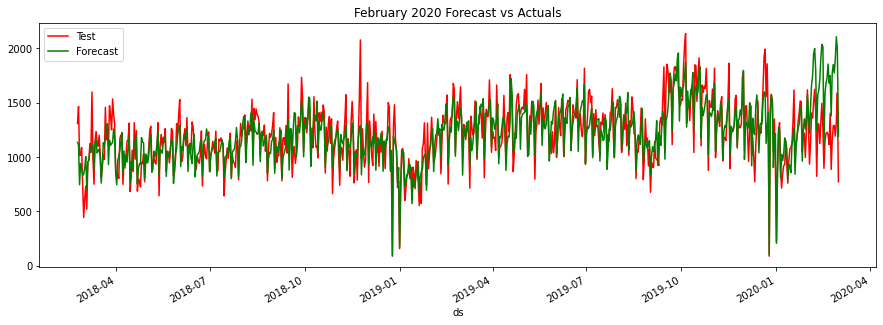

In [55]:
f1, ax1 = plt.subplots(figsize=(14,5))
f1.set_figheight(5)
f1.set_figwidth(15)
original_data_f.plot(kind='line',x='ProccessedDate', y='pedestrianCount', color='red', label='Test', ax=ax1)
forecast_data1.plot(kind='line',x='ds',y='yhat', color='green',label='Forecast', ax=ax1)
plt.title('February 2020 Forecast vs Actuals')
plt.show()

In [56]:
file = pd.read_csv(FOOTFALL_FILE) # reading footfall data
file= file[file['pedestrianCount'] != 0]
file = process_data(file) # process_data function has the data-processing functionality
temp_file = file[file['LocationName']=='Argyll St.'] 

In [57]:
mask1 = temp_file[(temp_file['ProccessedDate']>datetime.date(2018,1,1)) & (temp_file['ProccessedDate']<=datetime.date(2020,1,31))]
mask2 = temp_file[(temp_file['ProccessedDate'] > datetime.date(2020,2,1)) & (temp_file['ProccessedDate'] <= datetime.date(2020,3,1))]
train = mask1
test = mask2
df = train
original_data = train.append(test)

In [58]:
train = train.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
train['y_orig'] = train['y'] # to save a copy of the original data..you'll see why shortly. 
train['y'] = np.log(train['y'])

In [60]:
# initating prophet model with weekly and yearly seasonality to be true
model = Prophet(weekly_seasonality=True,yearly_seasonality=True, daily_seasonality=True) 
# adding custom seasonlity - daily with the period = 1 and the fourier order to be 15 
# model.add_seasonality(name='daily', period=1, fourier_order=15)
# adding the country's  holiday
model.add_country_holidays(country_name='UK')
# adding the multivariate variables to the model
model.add_regressor('Temperature')
model.add_regressor('tmin')
model.add_regressor('tmax')
model.add_regressor('wspd')
# now fitting the model with the training data
model.fit(train)
''' 'year': 'A',
        'quarter': 'Q',
        'month': 'M',
        'day': 'D',
        'hour': 'H',
        'minute': 'T',
        'second': 'S',
        'millisecond': 'L',
        'microsecond': 'U',
        'nanosecond': 'N'}1
'''

future_data = model.make_future_dataframe(periods=90)
df=df.append(test)
df = df.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
future_data=df[[ 'ds','Temperature', 'tmin', 'tmax','wspd']]

forecast_data = model.predict(future_data)

In [61]:
from fbprophet.plot import plot_plotly
plot_plotly(model,forecast_data)

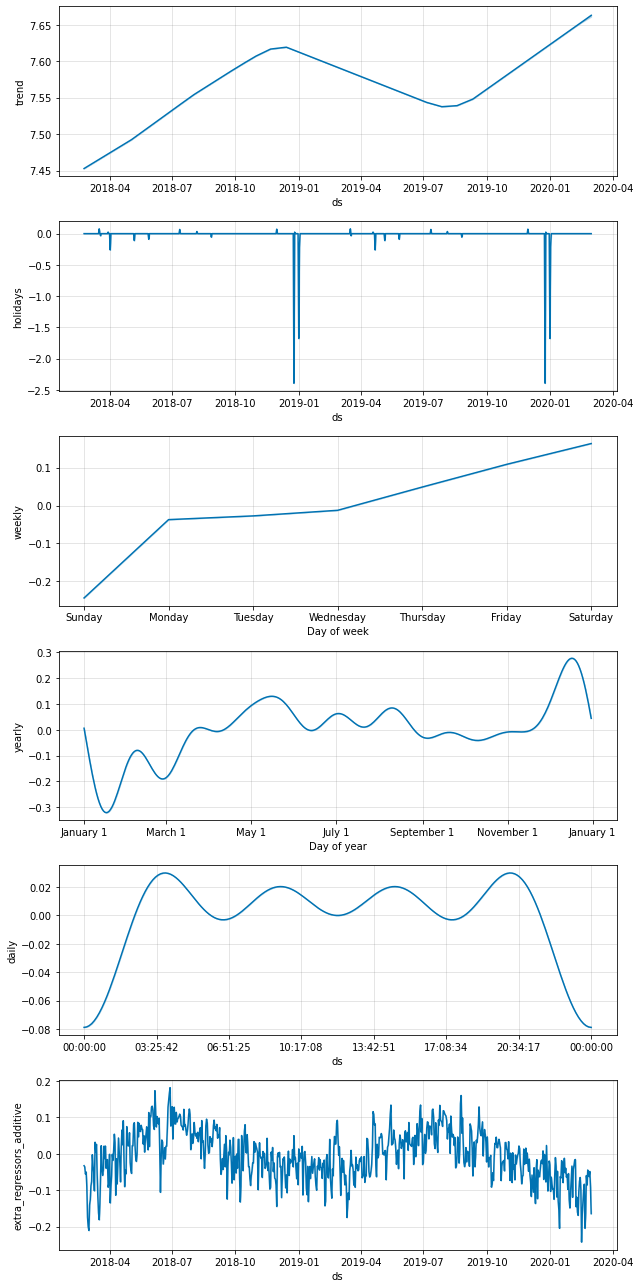

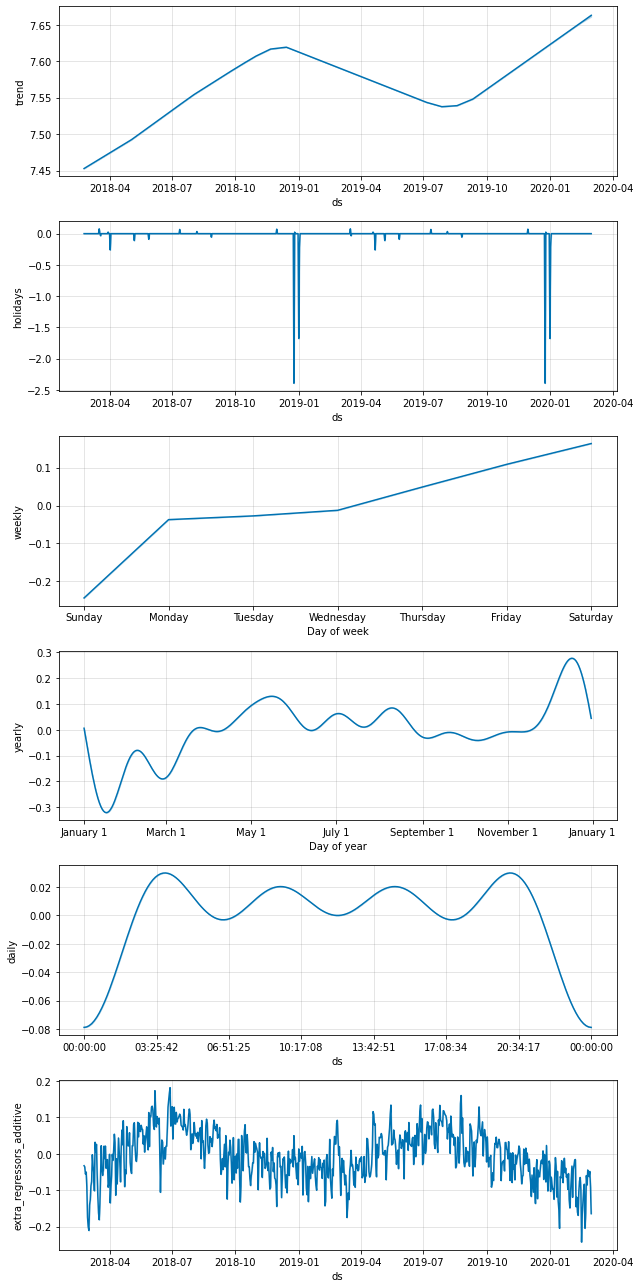

In [62]:
model.plot_components(forecast_data)


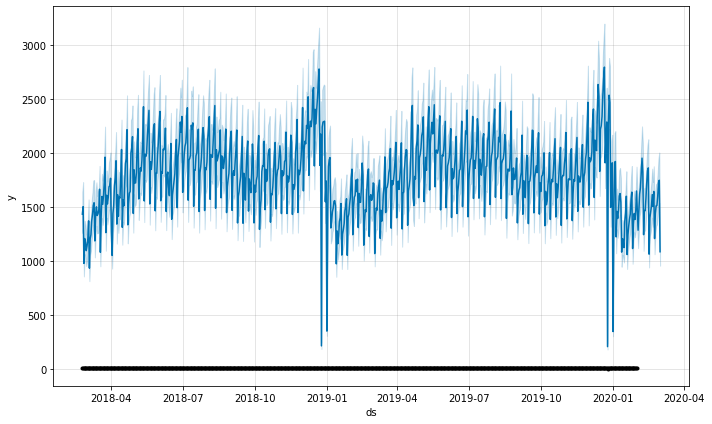

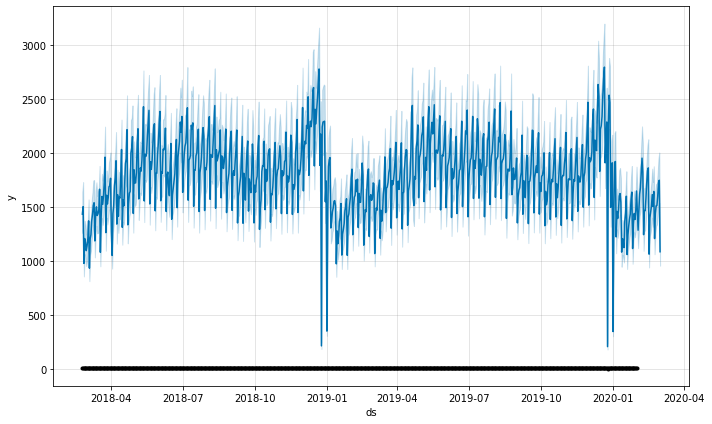

In [63]:
forecast_data_orig = forecast_data # make sure we save the original forecast data
forecast_data_orig['yhat'] = np.exp(forecast_data_orig['yhat'])
forecast_data_orig['yhat_lower'] = np.exp(forecast_data_orig['yhat_lower'])
forecast_data_orig['yhat_upper'] = np.exp(forecast_data_orig['yhat_upper'])

model.plot(forecast_data_orig)

In [65]:
train['y_log']=train['y'] #copy the log-transformed data to another column
train['y']=train['y_orig']

In [66]:
final_df = pd.DataFrame(forecast_data_orig)
import plotly.graph_objs as go
import plotly.offline as py
#Plot predicted and actual line graph with X=dates, Y=Outbound
actual_chart = go.Scatter(y=train["y_orig"], name= 'Actual')
predict_chart = go.Scatter(y=final_df["yhat"], name= 'Predicted')
predict_chart_upper = go.Scatter(y=final_df["yhat_upper"], name= 'Predicted Upper')
predict_chart_lower = go.Scatter(y=final_df["yhat_lower"], name= 'Predicted Lower')
py.plot([actual_chart, predict_chart, predict_chart_upper, predict_chart_lower])

'temp-plot.html'

In [68]:
strt='2020-02-01'
end='2020-03-01'
Actual = final_df[(final_df['ds']>strt) & (final_df['ds']<=end)]
mape = mean_absolute_percentage_error(test['pedestrianCount'],Actual['yhat'])
print("MAPE",round(mape,4))

MAPE 12.045


In [69]:
strt='2020-2-1'
end='2020-03-1'

model_parameters = pd.DataFrame(columns = ['MAPE','Parameters'])
for p in grid:
    mask1_h = temp_file[(temp_file['ProccessedDate']>datetime.date(2018,1,1)) & (temp_file['ProccessedDate']<=datetime.date(2020,1,31))]
    mask2_h = temp_file[(temp_file['ProccessedDate'] > datetime.date(2020,2,1)) & (temp_file['ProccessedDate'] <= datetime.date(2020,3,1))]
    train_h = mask1_h
    test_h = mask2_h
    df_h = train_h
    original_data_h = train_h.append(test)

    train_h = train_h.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
    # train_h['y_orig'] = train_h['y'] # to save a copy of the original data..you'll see why shortly. 
    # train_h['y'] = np.log(train_h['y'])
    testAc = pd.DataFrame()
    print(p)
    random.seed(0)
    train_model =Prophet(changepoint_prior_scale = p['changepoint_prior_scale'],
                         holidays_prior_scale = p['holidays_prior_scale'],
                         n_changepoints = p['n_changepoints'],
                         seasonality_mode = p['seasonality_mode'],
                         weekly_seasonality=True,
                         yearly_seasonality = True,
                         daily_seasonality=True,
                         holidays=holiday, 
                         interval_width=0.95)
    train_model.add_country_holidays(country_name='UK')
    train_model.fit(train_h)
    train_forecast = train_model.make_future_dataframe(periods=90)
    train_forecast = train_model.predict(train_forecast)
    test=train_forecast[['ds','yhat']]
    Actual = test[(test['ds']>strt) & (test['ds']<=end)]
    MAPE = mean_absolute_percentage_error(test_h['pedestrianCount'],abs(Actual['yhat']))
    print('Mean Absolute Percentage Error(MAPE)------------------------------------',MAPE)
    model_parameters = model_parameters.append({'MAPE':MAPE,'Parameters':p},ignore_index=True)

{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 100, 'seasonality_mode': 'multiplicative'}
Mean Absolute Percentage Error(MAPE)------------------------------------ 12.184270925159524
{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 100, 'seasonality_mode': 'additive'}
Mean Absolute Percentage Error(MAPE)------------------------------------ 13.248993553624988
{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 150, 'seasonality_mode': 'multiplicative'}
Mean Absolute Percentage Error(MAPE)------------------------------------ 12.119683902646845
{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 150, 'seasonality_mode': 'additive'}
Mean Absolute Percentage Error(MAPE)------------------------------------ 13.143163866714511
{'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 0.1, 'n_changepoints': 200, 'seasonality_mode': 'multiplicative'}
Mean Absolute Percentage Erro

In [70]:
parameters = model_parameters.sort_values(by=['MAPE'])
parameters = parameters.reset_index(drop=True)
parameters.head()

,MAPE,Parameters
0,12.072505,"{'changepoint_prior_scale': 0.2, 'holidays_pri..."
1,12.098678,"{'changepoint_prior_scale': 0.2, 'holidays_pri..."
2,12.119684,"{'changepoint_prior_scale': 0.1, 'holidays_pri..."
3,12.120501,"{'changepoint_prior_scale': 0.3, 'holidays_pri..."
4,12.120506,"{'changepoint_prior_scale': 0.2, 'holidays_pri..."


In [71]:
parameters['Parameters'][0]

{'changepoint_prior_scale': 0.2,
 'holidays_prior_scale': 0.1,
 'n_changepoints': 100,
 'seasonality_mode': 'multiplicative'}

In [100]:
from sklearn.model_selection import train_test_split
from fbprophet import Prophet
from sklearn.metrics import mean_squared_error
temp_file1 = file[file['LocationName']=='Argyll St.']
mask = temp_file1[(temp_file1['ProccessedDate']>datetime.date(2018,1,1)) & (temp_file1['ProccessedDate']<=datetime.date(2020,1,31))]
mask_2 = temp_file1[(temp_file1['ProccessedDate'] > datetime.date(2020,2,1)) & (temp_file1['ProccessedDate'] <= datetime.date(2020,3,1))]
train_f = mask
test_f = mask_2
df_f = train_f
original_data_f = train_f.append(test_f)
train_f = train_f.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
train_f['y_orig'] = train_f['y'] # to save a copy of the original data..you'll see why shortly. 
train_f['y'] = np.log(train_f['y'])

final_model = Prophet( holidays=holiday,
                      changepoint_prior_scale= 0.2,
                      holidays_prior_scale = 0.1,
                      n_changepoints = 100,
                      seasonality_mode = 'multiplicative',
                      weekly_seasonality=True,
                      yearly_seasonality = True,
                      interval_width=0.95) #instantiate Prophet
final_model.add_country_holidays(country_name='UK')
final_model.add_regressor('Temperature')
final_model.add_regressor('tmin')
final_model.add_regressor('tmax')
final_model.add_regressor('wspd')

In [101]:
final_model.fit(train_f)

''' 'year': 'A',
        'quarter': 'Q',
        'month': 'M',
        'day': 'D',
        'hour': 'H',
        'minute': 'T',
        'second': 'S',
        'millisecond': 'L',
        'microsecond': 'U',
        'nanosecond': 'N'}
'''

#future_data = model.make_future_dataframe(periods=6, freq = 'H')
future_data1 = final_model.make_future_dataframe(periods=90)

INFO:fbprophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


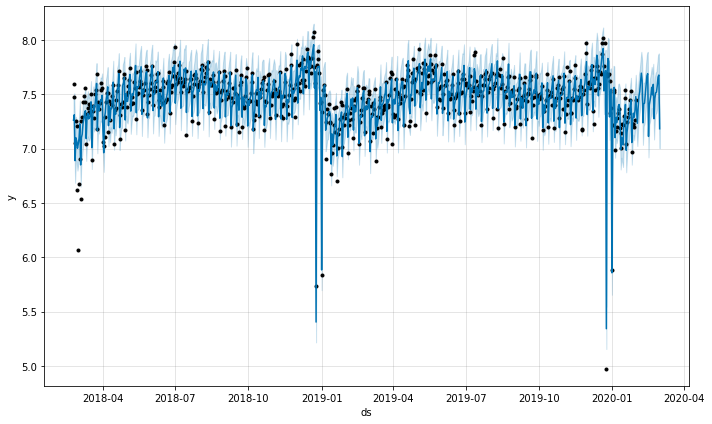

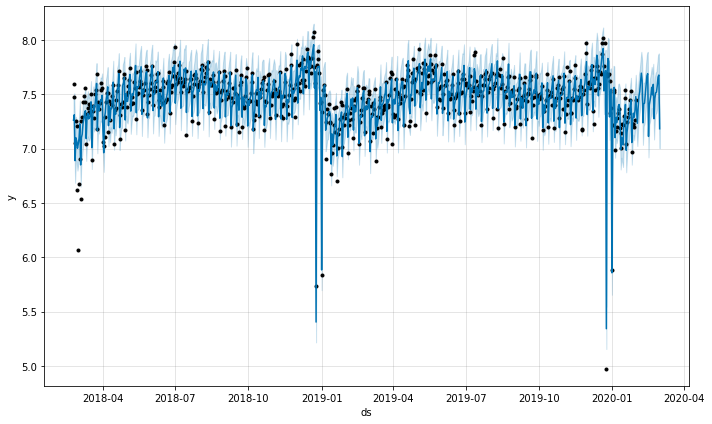

In [102]:
df_f=df_f.append(test_f)
df_f = df_f.rename(columns={'pedestrianCount': 'y', 'ProccessedDate':'ds'})
future_data=df_f[[ 'ds','Temperature', 'tmin', 'tmax','wspd']]
forecast_data = final_model.predict(future_data)
final_model.plot(forecast_data)

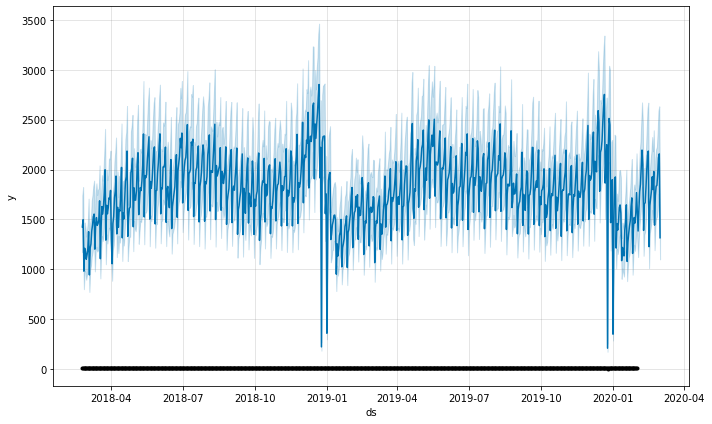

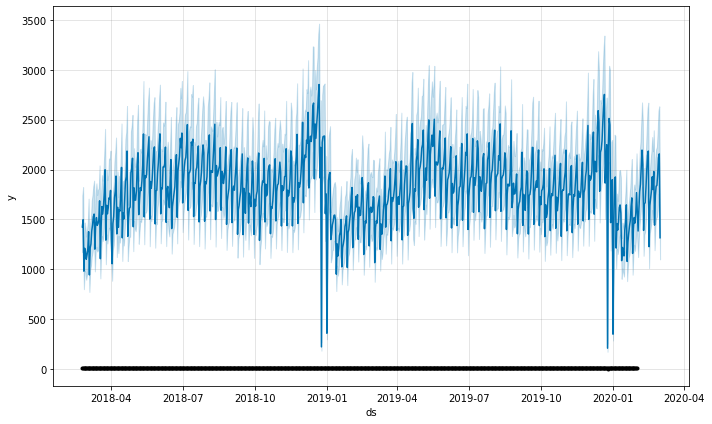

In [103]:
forecast_data[['ds', 'yhat', 'yhat_lower', 'yhat_upper']]
forecast_data_orig = forecast_data # make sure we save the original forecast data
forecast_data_orig['yhat'] = np.exp(forecast_data_orig['yhat'])
forecast_data_orig['yhat_lower'] = np.exp(forecast_data_orig['yhat_lower'])
forecast_data_orig['yhat_upper'] = np.exp(forecast_data_orig['yhat_upper'])

final_model.plot(forecast_data_orig)

In [96]:
train_f['y_log']=train_f['y'] #copy the log-transformed data to another column
train_f['y']=train_f['y_orig']
final_df = pd.DataFrame(forecast_data_orig)
import plotly.graph_objs as go
import plotly.offline as py
#Plot predicted and actual line graph with X=dates, Y=Outbound
actual_chart = go.Scatter(y=train["y_orig"], name= 'Actual')
predict_chart = go.Scatter(y=final_df["yhat"], name= 'Predicted')
predict_chart_upper = go.Scatter(y=final_df["yhat_upper"], name= 'Predicted Upper')
predict_chart_lower = go.Scatter(y=final_df["yhat_lower"], name= 'Predicted Lower')
py.plot([actual_chart, predict_chart, predict_chart_upper, predict_chart_lower])
strt='2020-02-01'
end='2020-03-01'
Actual = final_df[(final_df['ds']>strt) & (final_df['ds']<=end)]
mape = mean_absolute_percentage_error(test_f['pedestrianCount'],Actual['yhat'])
print("MAPE",round(mape,4))

MAPE 29.9253
